In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(360, 360)


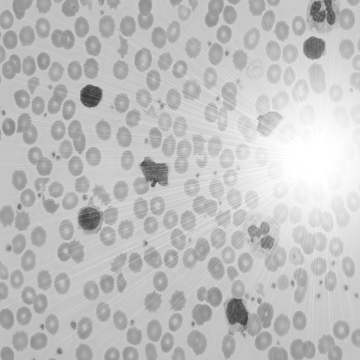

In [16]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/cell-bright.bmp')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gimg1 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print(gimg1.shape)
cv2_imshow(gimg1)

In [21]:
N = 10

dimh = np.int32(gimg1.shape[0]/N)
dimw = np.int32(gimg1.shape[1]/N)
print(dimh, dimw)

resh = np.int32(gimg1.shape[0] % N)
resw = np.int32(gimg1.shape[1] % N)
print(resh, resw)

meanimg = np.zeros((N,N))
outimg = np.zeros((gimg1.shape[0], gimg1.shape[1]))

36 36
0 0


In [22]:
def mean_func(img, dimh, dimw, h, w):
  sum = 0
  count = 0
  avg = 0

  for i in range(h, h+dimh):
    for j in range(w, w+dimw):
      sum += img[i,j]
      count += 1

  avg = np.int32(sum / count)
  return avg

In [25]:
for h in range(0, gimg1.shape[0] - resh, dimh):
  for w in range(0, gimg1.shape[1] - resw, dimw):
    meanimg[np.int32(h/dimh), np.int32(w/dimw)] = mean_func(gimg1, dimh, dimw, h, w)

cv2_imshow(meanimg)

/tmp/ipykernel_584/2869278212.py:8: RuntimeWarning: overflow encountered in scalar add
  sum += img[i,j]


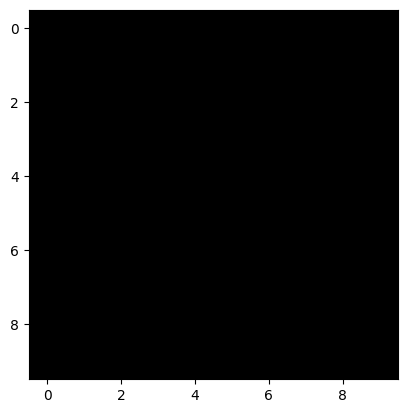

In [26]:
plt.imshow(meanimg, cmap = 'gray')

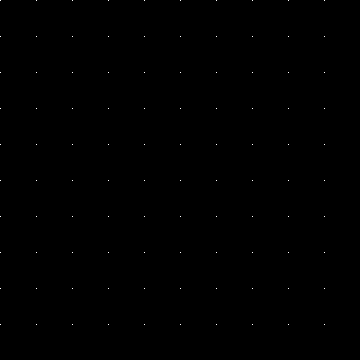

In [27]:
for h in range(0, gimg1.shape[0] - resh, dimh):
  for w in range(0, gimg1.shape[1] - resw, dimw):
    if(gimg1[h,w] > meanimg[np.int32(h/dimh), np.int32(w/dimw)]):
      outimg[h,w] = 255
    else:
      outimg[h,w] = 0

cv2_imshow(outimg)